# Prompt Piper — end-to-end walkthrough

This notebook walks through every layer of the library:

1. **Transformations** — apply operators individually and as a pipeline  
2. **Evaluators & tokenizers** — score and count tokens  
3. **Dataset** — build a sample dataset  
4. **Experiment** — run the multi-objective search, inspect the Pareto front  
5. **Baselines** — compare against no-compression / all-transformations / random search  
6. **Generation history** — trace convergence over generations  
7. **Template vs full-prompt compression** — compare `compress_field` modes  
8. **Operator frequency analysis** — which operators dominate the Pareto front  
9. **Data-driven fitting** — mine the corpus to adapt O3/O5/O17/O18/O22 lists  
10. **CompressorRunner** — the CLI-level runner with YAML config  
11. **Real LM Eval backend** — swapping in a real model (GPU required)  

Everything up to section 10 runs on CPU with `MockEvaluator` — no model or GPU needed.

In [1]:
import sys
sys.path.insert(0, "../src")

# Optional: wider output
import pandas as pd
pd.set_option("display.max_colwidth", 120)

## 1. Transformations

Each of the 28 operators is a callable that takes a string and returns a (possibly shorter) string.  
They are split into four categories: **lexical** (O1–O8), **syntactic** (O9–O13), **structural** (O14–O22), **semantic** (O23–O28).

In [2]:
from prompt_piper.transformations import ALL_TRANSFORMATIONS

# Show all 28 operators
rows = [{"id": T.id, "name": T.name, "category": T.category} for T in ALL_TRANSFORMATIONS]
pd.DataFrame(rows)

,id,name,category
0,O1,RemoveExtraWhitespace,lexical
1,O2,TrimSpaces,lexical
2,O3,RemoveStopwords,lexical
3,O4,ReplaceWithShortSynonym,lexical
4,O5,AbbreviationSubstitution,lexical
5,O6,SymbolSubstitution,lexical
6,O7,ContractionSubstitution,lexical
7,O8,RemovePolitenessMarkers,lexical
8,O9,SentenceMerge,syntactic
9,O10,ImperativeRewrite,syntactic


In [3]:
from prompt_piper.transformations import (
    RemoveExtraWhitespace, TrimSpaces, RemoveStopwords,
    ContractionSubstitution, RemovePolitenessMarkers,
    SentenceMerge, ClauseDeletion,
    DeduplicateInstructions, RemovePromptHeader,
)

SAMPLE_PROMPT = """\
## Task Instructions

Please kindly answer the following question carefully and thoroughly.
You are required to provide a concise answer.
You are required to provide a concise answer.

Context: The quick brown fox jumps over the lazy dog. \
The fox is very quick and the dog is very lazy.

Question: What does the fox do?
Options:
A) Sits
B) Jumps
C) Sleeps
Answer:"""

print(f"Original ({len(SAMPLE_PROMPT.split())} words):\n")
print(SAMPLE_PROMPT)

Original (63 words):

## Task Instructions

Please kindly answer the following question carefully and thoroughly.
You are required to provide a concise answer.
You are required to provide a concise answer.

Context: The quick brown fox jumps over the lazy dog. The fox is very quick and the dog is very lazy.

Question: What does the fox do?
Options:
A) Sits
B) Jumps
C) Sleeps
Answer:


In [4]:
# Apply operators one at a time and observe each change
operators = [
    RemovePolitenessMarkers(),  # removes "kindly", "carefully", "thoroughly"
    DeduplicateInstructions(),  # removes the repeated sentence
    RemovePromptHeader(),       # removes "## Task Instructions"
    RemoveExtraWhitespace(),    # collapses blank lines
    ClauseDeletion(),           # removes subordinate clauses
]

text = SAMPLE_PROMPT
for op in operators:
    result = op(text)
    removed = len(text.split()) - len(result.split())
    print(f"[{op.id}] {op.name}  → -{removed} words")
    print(result)
    print("─" * 60)
    text = result

[O8] RemovePolitenessMarkers  → -2 words
## Task Instructions

Answer the following question carefully and thoroughly.
You are required to provide a concise answer.
You are required to provide a concise answer.

Context: The quick brown fox jumps over the lazy dog. The fox is very quick and the dog is very lazy.

Question: What does the fox do?
Options:
A) Sits
B) Jumps
C) Sleeps
Answer:
────────────────────────────────────────────────────────────
[O14] DeduplicateInstructions  → -8 words
## Task Instructions

Answer the following question carefully and thoroughly. You are required to provide a concise answer. Context: The quick brown fox jumps over the lazy dog. The fox is very quick and the dog is very lazy. Question: What does the fox do? Options:
A) Sits
B) Jumps
C) Sleeps
Answer:
────────────────────────────────────────────────────────────
[O15] RemovePromptHeader  → -3 words
Answer the following question carefully and thoroughly. You are required to provide a concise answer. Cont

## 2. Evaluators and tokenizers

`Evaluator.evaluate(original, compressed, sample) → float [0, 1]`  
`Tokenizer.count(text) → int`

`MockEvaluator` simulates the intuition that heavier compression degrades performance.

In [5]:
from prompt_piper.optimization.evaluator import MockEvaluator
from prompt_piper.optimization.tokenizer import WhitespaceTokenizer, CharTokenizer

evaluator = MockEvaluator(alpha=0.5, noise_std=0.0)  # noise_std=0 for deterministic output
tokenizer = WhitespaceTokenizer()

original = SAMPLE_PROMPT
compressed = text  # result of the pipeline above

print(f"Original  : {tokenizer.count(original):3d} tokens")
print(f"Compressed: {tokenizer.count(compressed):3d} tokens")
print(f"Ratio     : {tokenizer.count(compressed) / tokenizer.count(original):.2%} of original")
print()
score = evaluator.evaluate(original, compressed, sample={})
print(f"MockEvaluator score: {score:.3f}  (1.0 = perfect, degrades with compression)")

Original  :  63 tokens
Compressed:  50 tokens
Ratio     : 79.37% of original

MockEvaluator score: 0.884  (1.0 = perfect, degrades with compression)


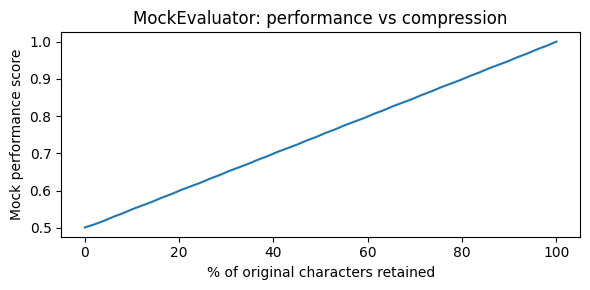

In [6]:
# Sweep compression ratios to visualise the mock performance curve
import matplotlib.pyplot as plt
import numpy as np

ratios = np.linspace(0, 1, 50)
scores = []
for r in ratios:
    # Simulate a prompt compressed to `r` fraction of the original length
    fake_compressed = original[: max(1, int(len(original) * r))]
    scores.append(MockEvaluator(alpha=0.5, noise_std=0.0).evaluate(original, fake_compressed, {}))

plt.figure(figsize=(6, 3))
plt.plot(ratios * 100, scores)
plt.xlabel("% of original characters retained")
plt.ylabel("Mock performance score")
plt.title("MockEvaluator: performance vs compression")
plt.tight_layout()
plt.show()

## 3. Dataset

A dataset is a list of dicts, each with at minimum a `"prompt"` key. For 0-shot compression experiments, add a `"prompt_0shot"` key with the version of the same prompt that has no few-shot examples prepended.

With the real `LMEvalBackend` you'd call `LMEvalBackend.build("hf", model_name, task_name)` and it builds the dataset from lm-eval. Here we build a synthetic one by hand.

In [7]:
TEMPLATES = [
    "Please kindly answer the question below carefully.\nQuestion: {q}\nAnswer:",
    "Your task is to answer the following question thoroughly.\nQuestion: {q}\nAnswer:",
    "Could you please provide a concise and accurate answer?\nQuestion: {q}\nAnswer:",
    "You are required to provide an answer to the question.\n{q}\nAnswer:",
    "In order to complete this task, read the question and answer.\n{q}\nAnswer:",
]
QUESTIONS = [
    "What is the capital of France?",
    "Who wrote Romeo and Juliet?",
    "What is the speed of light?",
    "What does HTTP stand for?",
    "What is the boiling point of water?",
]
FEW_SHOT_PREFIX = (
    "Example: What is 2+2? Answer: 4\n"
    "Example: What color is the sky? Answer: blue\n\n"
)

dataset = []
for i in range(20):
    template = TEMPLATES[i % len(TEMPLATES)].format(q=QUESTIONS[i % len(QUESTIONS)])
    dataset.append({
        "prompt":     FEW_SHOT_PREFIX + template,   # full formatted (with few-shot)
        "prompt_0shot": template,                    # same item, no few-shot examples
        "target":     ["Paris", "Shakespeare", "299,792,458 m/s", "HyperText Transfer Protocol", "100°C"][i % 5],
    })

print(f"Dataset: {len(dataset)} samples\n")
print("Sample 0 — full prompt:")
print(dataset[0]["prompt"])
print("\nSample 0 — 0-shot prompt:")
print(dataset[0]["prompt_0shot"])

Dataset: 20 samples

Sample 0 — full prompt:
Example: What is 2+2? Answer: 4
Example: What color is the sky? Answer: blue

Please kindly answer the question below carefully.
Question: What is the capital of France?
Answer:

Sample 0 — 0-shot prompt:
Please kindly answer the question below carefully.
Question: What is the capital of France?
Answer:


## 4. Running the optimisation search

`Experiment` wires together the dataset, evaluator, tokenizer, and transformation search space.  
`ExperimentConfig` controls the algorithm and budget.  

The search finds the **Pareto front**: solutions that are non-dominated in the (tokens, performance) space — i.e. no other solution is both shorter *and* better.

In [8]:
from prompt_piper.optimization import Experiment, ExperimentConfig
from prompt_piper.optimization.evaluator import MockEvaluator

config = ExperimentConfig(
    algorithm="nsga2",
    pop_size=20,
    n_gen=30,
    n_subset=10,        # samples used per fitness evaluation
    subset_seed=42,
    seed=42,
)

exp = Experiment(
    config=config,
    dataset=dataset,
    evaluator=MockEvaluator(alpha=0.5, noise_std=0.02, seed=0),
)

result = exp.run(baselines=["no_compression", "all_transformations", "random_search", "multi_armed_bandit"])
print(result.summary())

Experiment: NSGA2 | 30 gen × 20 pop | 0.8s
Pareto front: 1 solutions
  Token range:       30.1 – 30.1
  Performance range: 1.000 – 1.000
Baselines:
  no_compression: tokens=30.1, perf=0.989
  all_transformations: tokens=30.1, perf=0.941
  random_search: tokens=30.1, perf=1.000
  multi_armed_bandit: tokens=30.1, perf=0.994


## 5. Inspecting the Pareto front

Each Pareto solution is a binary mask over the 28 operators.  
The front visualises the trade-off: moving left = fewer tokens, moving up = better performance.

In [9]:
# Tabular view of every Pareto solution
rows = []
for bits, names, tokens, perf in zip(
    result.pareto_solutions,
    result.pareto_transformation_names,
    result.avg_tokens,
    result.avg_performance,
):
    rows.append({
        "avg_tokens": round(float(tokens), 2),
        "avg_performance": round(float(perf), 3),
        "n_operators": int(bits.sum()),
        "operators": ", ".join(names) if names else "(none)",
    })

df_pareto = pd.DataFrame(rows).sort_values("avg_tokens")
df_pareto

,avg_tokens,avg_performance,n_operators,operators
0,30.1,1.0,20,"I:RemoveExtraWhitespace, I:TrimSpaces, I:RemoveStopwords, I:ReplaceWithShortSynonym, I:SymbolSubstitution, I:Contrac..."


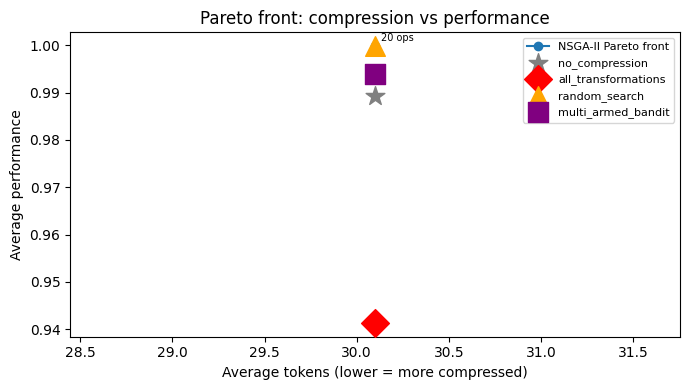

In [10]:
# Plot Pareto front + baselines
fig, ax = plt.subplots(figsize=(7, 4))

# Pareto front (sorted for a connected line)
sorted_idx = result.avg_tokens.argsort()
ax.plot(result.avg_tokens[sorted_idx], result.avg_performance[sorted_idx],
        "o-", label="NSGA-II Pareto front", zorder=3)

# Annotate each solution with its operator count
for tokens, perf, bits in zip(result.avg_tokens, result.avg_performance, result.pareto_solutions):
    ax.annotate(f"{int(bits.sum())} ops", (tokens, perf),
                textcoords="offset points", xytext=(4, 4), fontsize=7)

# Baselines
colors = {
    "no_compression":    "gray",
    "all_transformations": "red",
    "random_search":     "orange",
    "multi_armed_bandit": "purple",
}
markers = {
    "no_compression":    "*",
    "all_transformations": "D",
    "random_search":     "^",
    "multi_armed_bandit": "s",
}
for name, br in result.baselines.items():
    ax.scatter(br.avg_tokens.mean(), br.avg_performance.mean(),
               marker=markers.get(name, "o"), s=200, zorder=4,
               label=name, color=colors.get(name))

ax.set_xlabel("Average tokens (lower = more compressed)")
ax.set_ylabel("Average performance")
ax.set_title("Pareto front: compression vs performance")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
# Two extreme points on the Pareto front
bits_best_perf, tokens_bp, perf_bp = result.best_performance()
bits_best_comp, tokens_bc, perf_bc = result.best_compression()

print("Best performance solution:")
print(f"  tokens={tokens_bp:.1f}, performance={perf_bp:.3f}")
ops_bp = [T.name for T, b in zip([T() for T in ALL_TRANSFORMATIONS], bits_best_perf) if b]
print(f"  operators ({len(ops_bp)}): {ops_bp}\n")

print("Best compression solution:")
print(f"  tokens={tokens_bc:.1f}, performance={perf_bc:.3f}")
ops_bc = [T.name for T, b in zip([T() for T in ALL_TRANSFORMATIONS], bits_best_comp) if b]
print(f"  operators ({len(ops_bc)}): {ops_bc}")

Best performance solution:
  tokens=30.1, performance=1.000
  operators (17): ['RemoveExtraWhitespace', 'TrimSpaces', 'RemoveStopwords', 'ReplaceWithShortSynonym', 'SymbolSubstitution', 'ContractionSubstitution', 'RemovePolitenessMarkers', 'SentenceMerge', 'ImperativeRewrite', 'ClauseDeletion', 'RemovePromptHeader', 'RemoveMetaText', 'SectionPruning', 'ExampleRemoval', 'SchemaEncoding', 'ExampleDistillation', 'ChunkCompression']

Best compression solution:
  tokens=30.1, performance=1.000
  operators (17): ['RemoveExtraWhitespace', 'TrimSpaces', 'RemoveStopwords', 'ReplaceWithShortSynonym', 'SymbolSubstitution', 'ContractionSubstitution', 'RemovePolitenessMarkers', 'SentenceMerge', 'ImperativeRewrite', 'ClauseDeletion', 'RemovePromptHeader', 'RemoveMetaText', 'SectionPruning', 'ExampleRemoval', 'SchemaEncoding', 'ExampleDistillation', 'ChunkCompression']


In [ ]:
# Apply the best-compression pipeline to a sample prompt and inspect the output
from prompt_piper.transformations import ALL_TRANSFORMATIONS as ALL_T_CLASSES

best_comp_pipeline = [T() for T, b in zip(ALL_T_CLASSES, bits_best_comp) if b]

sample_prompt = dataset[0]["prompt"]
compressed_prompt = sample_prompt
for op in best_comp_pipeline:
    compressed_prompt = op(compressed_prompt)

print(f"Original  ({len(A.split())} words):\n{sample_prompt}\n")
print("─" * 60)
print(f"Compressed ({len(compressed_prompt.split())} words):\n{compressed_prompt}")

## 6. Generation history

The `GenerationCallback` snapshots the Pareto front after every generation.  
This lets you see how the front evolves and check whether the search has converged.

In [ ]:
from prompt_piper.tools.compressor.callback import GenerationCallback

transform_names = [T.name for T in ALL_T_CLASSES]
callback = GenerationCallback(transform_names)

result_with_history = exp.run(
    baselines=["no_compression", "all_transformations"],
    callback=callback,
)

print(f"Captured {len(callback.history)} generations")
print()

# Show first, middle, and last snapshots
for snapshot in [callback.history[0], callback.history[len(callback.history) // 2], callback.history[-1]]:
    gen = snapshot["generation"]
    n = snapshot["n_solutions"]
    min_tok = min(s["avg_tokens"] for s in snapshot["pareto_front"])
    max_perf = max(s["avg_performance"] for s in snapshot["pareto_front"])
    print(f"Gen {gen:3d}: {n} Pareto solutions | min_tokens={min_tok:.1f} | max_perf={max_perf:.3f}")

In [ ]:
# Plot convergence: best token count and best performance per generation
gens = [s["generation"] for s in callback.history]
min_tokens_per_gen = [min(sol["avg_tokens"] for sol in s["pareto_front"]) for s in callback.history]
max_perf_per_gen  = [max(sol["avg_performance"] for sol in s["pareto_front"]) for s in callback.history]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))

ax1.plot(gens, min_tokens_per_gen)
ax1.set_xlabel("Generation")
ax1.set_ylabel("Min avg tokens")
ax1.set_title("Best compression per generation")

ax2.plot(gens, max_perf_per_gen, color="orange")
ax2.set_xlabel("Generation")
ax2.set_ylabel("Max avg performance")
ax2.set_title("Best performance per generation")

plt.tight_layout()
plt.show()

## 7. Template vs full-prompt compression

`compress_field` controls which part of the prompt is compressed:

- `compress_field=None` (default) → compress `sample["prompt"]` — the **full formatted prompt** including few-shot examples  
- `compress_field="prompt_0shot"` → compress `sample["prompt_0shot"]` — only the **0-shot prompt**, leaving the few-shot context untouched

Both runs use the same dataset and evaluator so the Pareto fronts are directly comparable.

In [ ]:
shared_eval = MockEvaluator(alpha=0.5, noise_std=0.02, seed=0)
base_config = dict(algorithm="nsga2", pop_size=20, n_gen=30, n_subset=10, subset_seed=42, seed=42)

# Mode A: compress the full prompt (default behaviour)
result_full = Experiment(
    config=ExperimentConfig(**base_config),
    dataset=dataset,
    evaluator=shared_eval,
).run()

# Mode B: compress only the 0-shot prompt
result_tmpl = Experiment(
    config=ExperimentConfig(**base_config, compress_field="prompt_0shot"),
    dataset=dataset,
    evaluator=shared_eval,
).run()

print("Full-prompt mode — token range:",
      f"{result_full.avg_tokens.min():.1f} – {result_full.avg_tokens.max():.1f}")
print("0-shot mode      — token range:",
      f"{result_tmpl.avg_tokens.min():.1f} – {result_tmpl.avg_tokens.max():.1f}")
print()
print("(0-shot tokens are lower because few-shot text is not counted.)")

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

for res, label, color in [
    (result_full, "Full-prompt compression", "steelblue"),
    (result_tmpl, "Template-only compression", "darkorange"),
]:
    idx = res.avg_tokens.argsort()
    ax.plot(res.avg_tokens[idx], res.avg_performance[idx], "o-", label=label, color=color)

ax.set_xlabel("Average tokens in the compressed field")
ax.set_ylabel("Average performance")
ax.set_title("Pareto front: full-prompt vs template compression")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Operator frequency analysis

Which operators appear most on the Pareto front?  
Operators that appear in many Pareto solutions are robust choices — they compress without hurting performance across configurations.

In [ ]:
from collections import Counter

counts = Counter()
for names in result.pareto_transformation_names:
    counts.update(names)

if counts:
    ops, freqs = zip(*counts.most_common())
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.barh(list(ops)[::-1], list(freqs)[::-1])
    ax.set_xlabel("Frequency on Pareto front")
    ax.set_title("Most common operators across Pareto solutions")
    plt.tight_layout()
    plt.show()
else:
    print("No operators selected (all Pareto solutions are no-op).")

## 9. Data-driven transformation fitting

Some transformations operate on configurable lists — stopwords, abbreviation pairs, section headings, label maps.  
`DatasetVocabularyFitter` mines a corpus (typically the task's **training split**) to extend those lists with patterns specific to that dataset.

| Operator | What gets adapted | Requires LLM backend |
|---|---|---|
| O3 `RemoveStopwords` | High-frequency words not appearing in any target | No |
| O5 `AbbreviationSubstitution` | Recurring multi-word domain phrases → uppercase initials | No |
| O17 `ContextPruning` | Most frequent target-vocabulary words used as anchor terms | No |
| O18 `SectionPruning` | Section headings that recur across prompts; XML/HTML tag names | No (headings) / Yes (tags) |
| O21 `ExampleSimplification` | Input/output field marker names (e.g. `Passage:` / `Summary:`) | No |
| O22 `LabelShortening` | Unique label strings found in targets | No |
| O4 `ReplaceWithShortSynonym` | Domain-specific verbose phrases → shorter equivalents | Yes |
| O10 `ImperativeRewrite` | Dataset-specific task-framing patterns to strip | Yes |
| O15 `RemovePromptHeader` | Non-standard header formats (bold, XML, custom dividers) | Yes |
| O28 `ChunkCompression` | Block separator pattern used in this dataset | Yes |

The fitted instances slot in via the existing `transformation_factory` hook — no changes to the search pipeline.

In [ ]:
from prompt_piper.transformations import DatasetVocabularyFitter

# Use the existing dataset as a stand-in for a training corpus.
# In real usage this would be a separate training split:
#
#   from prompt_piper.backends.lm_eval import LMEvalDataset
#   train_dataset = LMEvalDataset.from_task_name(
#       "hellaswag", split="train", num_fewshot=5,
#       template_field="prompt_0shot",
#   ).as_list()
#
fitter = DatasetVocabularyFitter(
    dataset,
    prompt_field="prompt",      # field to analyse
    target_field="target",       # field whose values must never be removed
    sample_size=None,            # use all samples; set an int to subsample
    seed=42,
)
print(f"Corpus size: {len(fitter._corpus)} samples")

### 9a. Inspect what the fitter discovers

`fitter.report()` shows only the **newly mined** entries — things not already in the built-in defaults.

In [ ]:
report = fitter.report()

sections = {
    "New abbreviations (O5)":    [(p, r) for p, r in report["abbreviations"]],
    "New stopwords (O3)":        report["stopwords"],
    "New labels (O22)":          report["labels"],
    "New prunable sections (O18)": report["sections"],
    "Context anchor terms (O17)": report["context_anchors"],
}

for title, items in sections.items():
    print(f"{'─'*50}")
    print(f"  {title}")
    print(f"{'─'*50}")
    if not items:
        print("  (none beyond defaults)")
    elif isinstance(items, list) and items and isinstance(items[0], tuple):
        for pattern, replacement in items:
            print(f"  {pattern!r:50s} → {replacement!r}")
    elif isinstance(items, dict):
        for k, v in items.items():
            print(f"  {k!r} → {v!r}")
    else:
        for item in items:
            print(f"  {item}")
    print()

### 9b. Apply fitted transformations to a sample prompt

Compare the default O5 (built-in abbreviations only) against the corpus-fitted O5.

In [ ]:
from prompt_piper.transformations.lexical import AbbreviationSubstitution, RemoveStopwords

sample = dataset[0]["prompt"]
print(f"Original ({len(sample.split())} words):\n{sample}\n")
print("─" * 60)

default_abbrev  = AbbreviationSubstitution()
fitted_abbrev   = fitter.fit_abbreviation_substitution(min_doc_freq=0.3)

out_default = default_abbrev(sample)
out_fitted  = fitted_abbrev(sample)

print(f"Default O5  ({len(out_default.split())} words):\n{out_default}\n")
print("─" * 60)
print(f"Fitted O5   ({len(out_fitted.split())} words):\n{out_fitted}")

In [ ]:
from prompt_piper.transformations.structural import LabelShortening

# Fit O22 — compare default vs corpus-fitted label map
default_labels = LabelShortening()
fitted_labels  = fitter.fit_label_shortening()

print("Default label map:", default_labels._map)
print()
print("Fitted label map (all entries, including new ones from targets):")
print(fitted_labels._map)

# Apply to a prompt containing labels from the dataset
sample_with_labels = "Options:\nA) Paris\nB) London\nC) Berlin\nD) Rome\nAnswer: Paris"
print(f"\nOriginal:\n{sample_with_labels}")
print(f"\nDefault  O22: {default_labels(sample_with_labels)}")
print(f"Fitted   O22: {fitted_labels(sample_with_labels)}")

### 9c. Run the search with fitted vs default transformations

Pass `make_transformation_factory()` to `Experiment` and compare Pareto fronts.

In [ ]:
shared_eval = MockEvaluator(alpha=0.5, noise_std=0.02, seed=0)
search_cfg = ExperimentConfig(algorithm="nsga2", pop_size=20, n_gen=30,
                               n_subset=10, subset_seed=42, seed=42)

# Default: every transformation is instantiated with no-arg constructor
result_default = Experiment(
    config=search_cfg,
    dataset=dataset,
    evaluator=shared_eval,
).run(baselines=["no_compression"])

# Fitted: O3/O5/O17/O18/O22 use corpus-adapted instances
fitted_factory = fitter.make_transformation_factory(
    extend_default=True,               # merge with built-in lists
    abbreviation_min_doc_freq=0.3,     # phrase must appear in ≥30% of docs
    stopword_min_doc_freq=0.85,        # word must appear in ≥85% of docs
)
result_fitted = Experiment(
    config=search_cfg,
    dataset=dataset,
    evaluator=shared_eval,
    transformation_factory=fitted_factory,
).run(baselines=["no_compression"])

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

for res, label, color in [
    (result_default, "Default transformations", "steelblue"),
    (result_fitted,  "Corpus-fitted transformations", "darkorange"),
]:
    idx = res.avg_tokens.argsort()
    ax.plot(res.avg_tokens[idx], res.avg_performance[idx], "o-", label=label, color=color)

# No-compression baseline (same for both runs)
nc = result_default.baselines["no_compression"]
ax.scatter(nc.avg_tokens.mean(), nc.avg_performance.mean(),
           marker="*", s=250, color="gray", zorder=5, label="no_compression")

ax.set_xlabel("Average tokens")
ax.set_ylabel("Average performance")
ax.set_title("Default vs corpus-fitted transformations")
ax.legend()
plt.tight_layout()
plt.show()

# Print min-token solution for each
for label, res in [("Default", result_default), ("Fitted", result_fitted)]:
    bits, tok, perf = res.best_compression()
    names = [T.name for T, b in zip([T() for T in ALL_TRANSFORMATIONS], bits) if b]
    print(f"{label:8s}  best compression: {tok:.1f} tok / {perf:.3f} perf  ({len(names)} ops)")

## 9. CompressorRunner (CLI-level tool)

`CompressorRunner` is what the CLI calls. It loads the model once, iterates over all runs defined in a `CompressorConfig`, and writes one JSON result file per run. Here we use `dry_run=True` so no model is needed.

In [ ]:
from prompt_piper.tools.compressor.config import CompressorConfig
from prompt_piper.tools.compressor.runner import CompressorRunner

cfg = CompressorConfig.from_dict({
    "model": {"type": "hf", "name": "mistralai/Mistral-7B-v0.1"},
    "output": {"dir": "/tmp/pp_notebook_results", "overwrite": True},
    "defaults": {
        "n_search": 15,
        "n_test": 15,
        "pop_size": 10,
        "n_gen": 5,
        "seed": 42,
        "baselines": ["no_compression", "all_transformations", "random_search", "multi_armed_bandit"],
    },
    "runs": [
        {"name": "run_full_prompt",  "task": "hellaswag"},
        {"name": "run_0shot",        "task": "hellaswag", "compress_field": "prompt_0shot"},
    ],
})

runner = CompressorRunner(cfg, dry_run=True)
results = runner.run_all()

In [ ]:
for r in results:
    print(r.summary())
    print()

In [ ]:
# Load a result back from disk (the JSON is fully self-contained)
from prompt_piper.tools.compressor.results import CompressorResult
import json, pathlib

for path in sorted(pathlib.Path("/tmp/pp_notebook_results").glob("*.json")):
    cr = CompressorResult.load(path)
    print(f"Loaded: {path.name}")
    print(f"  compress_field : {cr.config['run']['compress_field']}")
    print(f"  Pareto solutions: {len(cr.pareto_solutions)}")
    best = min(cr.pareto_solutions, key=lambda s: s.search_avg_tokens)
    print(f"  Best compression: {best.search_avg_tokens:.1f} tok / {best.search_avg_performance:.3f} perf")
    print(f"  Operators: {best.transformation_names}\n")

## 10. Using a real LM Eval backend (GPU required)

Swap out `MockEvaluator` for the real model with a single facade call.  
The model is loaded once and reused for both the dataset, the evaluator, and the semantic backend (O23–O28).

```python
from prompt_piper.backends.lm_eval import LMEvalBackend
from prompt_piper.optimization import ExperimentConfig

backend = LMEvalBackend.build(
    model_type="hf",
    model_name="mistralai/Mistral-7B-v0.1",
    task_name="hellaswag",
    num_fewshot=5,           # few-shot count
    device="cuda",
    dtype="float16",
)

config = ExperimentConfig(
    algorithm="nsga2",
    pop_size=50,
    n_gen=100,
    n_subset=200,
    compress_field="prompt_0shot",   # or None for full-prompt mode
)

result = backend.build_experiment(
    config,
    split="validation",         # split used during search
    use_llm_for_semantic=True,  # LLM backend for O23-O28
).run(baselines=["no_compression", "all_transformations", "random_search"])

print(result.summary())
```

The `num_fewshot` setting controls how many few-shot examples lm-eval prepends to each prompt.  
Setting `compress_field="prompt_0shot"` compresses only the 0-shot part while keeping the few-shot demonstrations intact.